In [20]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "../utils/py")
import ramses_io

In [21]:
def read_last_output(path):
    snapshot = sorted(Path(path).glob("output_*"))[-1]
    time = ramses_io.rd_info_txt(snapshot / "info.txt")["time"]
    return time, ramses_io.leaf_cells(snapshot)

In [22]:
t0, out0 = read_last_output("../out/ramses2d_level4")
t1, out1 = read_last_output("../out/ramses_1dof2d_level4")

In [23]:
assert t0 == t1
assert out0.ndim == out1.ndim == 2
assert np.array_equal(out0.x, out1.x)
assert np.array_equal(out0.level, out1.level)
assert out0.names == out1.names
for name in out0.names:
    assert np.array_equal(out0[name], out1[name]), name

print(f"Final outputs agree exactly: {out0.ncell} cells, {len(out0.names)} hydro fields, t={t0}.")

Final outputs agree exactly: 256 cells, 5 hydro fields, t=1.00071051080008.


In [24]:
def analytical_sinus_rho(x, y, t):
    r = (x - 2.0 * t) + (y - 1.0 * t)
    return 1.5 + 0.5 * np.sin(2 * np.pi * r)

def analytical_sinus_rho_cell_averages(nx, ny, t, p):
    out = np.empty((nx, ny))
    hx, hy = 1.0 / nx, 1.0 / ny
    xfaces, yfaces = np.linspace(0, 1, nx + 1), np.linspace(0, 1, ny + 1)
    xcenters, ycenters = 0.5 * (xfaces[1:] + xfaces[:-1]), 0.5 * (yfaces[1:] + yfaces[:-1])

    ngl = p // 2 + 1
    xgl, wgl = np.polynomial.legendre.leggauss(ngl)
    ygl = xgl * hy / 2.0
    xgl = xgl * hx / 2.0
    wgl /= 2.0
    
    for i, xcen in enumerate(xcenters):
        for j, ycen in enumerate(ycenters):
            average = 0.0
            for dxgl, wgl1 in zip(xgl, wgl):
                for dygl, wgl2 in zip(ygl, wgl):
                    average += wgl1 * wgl2 * analytical_sinus_rho(xcen + dxgl, ycen + dygl, t)
            out[i, j] = average
    return out

def plot_error(ax, basepath, levellist, *, p, norm="l1", **kwargs):
    resolutionlist = []
    errorlist = []
    for lev in levellist:
        path = f"{basepath}_level{lev}"
        if not Path(path).exists():
            raise FileNotFoundError(path)
        t, out = read_last_output(path)
        assert np.all(out.level == out.level[0]), "Expected a uniform grid"
        nx = 2**int(out.level[0])
        ana = analytical_sinus_rho_cell_averages(nx, nx, t, p)[tuple(out.icell.T)]
        match norm:
            case "l1":
                error = np.mean(np.abs(out["density"] - ana))
            case _:
                raise ValueError(f"{norm=}")
        resolutionlist.append(nx)
        errorlist.append(error)
    ax.plot(resolutionlist, errorlist, **kwargs)

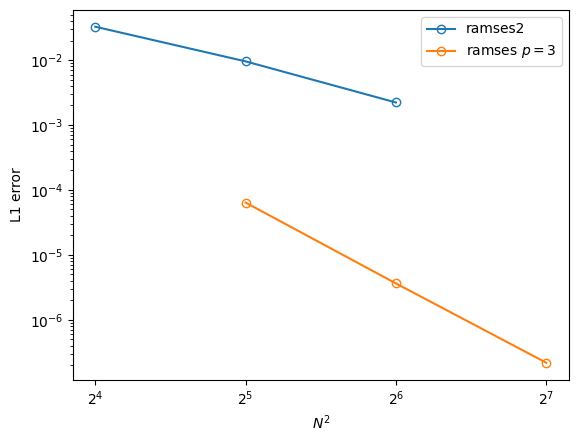

In [25]:
fig, ax = plt.subplots()
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel(r"$N^2$")
ax.set_ylabel("L1 error")

plot_config = dict(marker='o', mfc='none')
plot_error(ax, "../out/ramses2d", [4, 5, 6], p=1, label="ramses2", **plot_config)
plot_error(ax, "../out/ramses_2dof2d_p3", [4, 5, 6], p=3, label=r"ramses $p=3$", **plot_config)

ax.legend()